# Telco churn: exploratory data analysis

Funnel approach: check that the data conform to their definitions, hold out the test set, then profile every column, group them into families, rank them against churn and look closely at the few that matter.

Rules:
- **Sections A–B use the whole file.** Section A checks the format and the domain of every column and applies the cleaning (fixed rules per row, no target, no statistics). Section B splits off the hold-out set.
- **Sections 1–11 use the training set only**, so no decision that looks at churn is taken on the hold-out customers.
- **No imputation**: it belongs to the model pipeline, fitted on the training set.
- `Customer_ID` (key only) and `ethnic` (GDPR special category) are never features; only aggregates are shown, never customer rows.

All the logic lives in `src/churn/`; this notebook only calls it.

In [1]:
import pandas as pd
from sklearn.metrics import roc_auc_score

from churn import eda, plots
from churn.config import ROOT, load_config
from churn.data import clean, load_raw, na_tokens, split

cfg = load_config()
e, co = cfg["eda"], cfg["conformity"]
TARGET = cfg["target"]
RAW_PATH = ROOT / cfg["paths"]["raw_data"]
plots.set_style()
pd.set_option("display.float_format", "{:.4f}".format)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.max_rows", 200)
P_FORMAT = "{:.3g}".format  # tables with p-values: keeps tiny values readable

raw = load_raw(RAW_PATH)
print(f"{len(raw):,} rows, {raw.shape[1]} columns: {raw.select_dtypes('number').shape[1]} numeric, "
      f"{raw.select_dtypes(exclude='number').shape[1]} text")

100,000 rows, 100 columns: 79 numeric, 21 text


## A. Data conformity (whole file, no target)
Before any analysis: what "missing" looks like in the file, which codes mean "unknown", and which values the column definitions rule out. These checks use neither churn nor any statistic of the data, so they run on the whole file. The cleaning they lead to (`clean()` in `src/churn/data.py`, rules in `config.yaml`) is a fixed rule per row: it must work the same way on the hold-out set and on future customers.

First, the literal text of every cell that pandas' default reader would turn into NaN.

In [2]:
na_tokens(RAW_PATH)

,cells,n_columns,columns
token,,,
'',332781,43,"hnd_price, ownrent, dwlltype, dwllsize, numbcars, prizm_social_one, HHstatin, lor, adults, infobase, income, truck, ..."
'NA',10188,1,hnd_webcap


**Takeaway:** only two tokens stand for "missing": the empty cell (332,781 cells in 43 columns) and the literal `NA` (10,188 cells, all in `hnd_webcap`). A placeholder pandas does not recognise (UNKNOWN, ?, -) would show up as a level in the table of text columns below, or turn a numeric column into text: neither happens, and all 79 numeric columns parse as numbers. `load_raw` therefore treats only the empty cell as missing; whether `NA` is a missing value is checked next.

In [3]:
raw.groupby("hnd_webcap", dropna=False).agg(
    customers=("eqpdays", "size"), median_eqpdays=("eqpdays", "median"), median_hnd_price=("hnd_price", "median"),
    share_not_dualband=("dualband", lambda s: s.eq("N").mean()))

,customers,median_eqpdays,median_hnd_price,share_not_dualband
hnd_webcap,,,,
NA,10188,685.0000,29.9900,0.5528
UNKW,235,34.0000,NaN,0.0000
WC,13843,620.0000,29.9900,0.5818
WCMB,75733,307.0000,129.9900,0.1256
NaN,1,NaN,NaN,0.0000


**Takeaway: `NA` is a handset type, not a gap.** Its 10,188 handsets are old (median 685 days) and cheap (median price 29.99), and 55% are not dual-band: the profile of `WC` (620 days, 29.99, 58%) and the opposite of `WCMB` (307 days, 129.99, 13%). The file already has `UNKW` for an unknown capability, and only one cell is really empty. So `NA` stays a level (most likely no web capability), while `UNKW` becomes NaN below.

Levels of every text column, with the codes that mean "unknown" (from `config.yaml`, checked against the dictionary and these levels).

In [4]:
text = raw.select_dtypes(exclude="number").drop(columns=cfg["exclude"], errors="ignore")
codes = cfg["cleaning"]["unknown_codes"]
pd.DataFrame({
    "n_levels": text.nunique(),
    "levels": {c: ", ".join(sorted(text[c].dropna().unique())) for c in text},
    "unknown_code": {c: ", ".join(codes.get(c, [])) for c in text},
    "n_unknown": {c: int(text[c].isin(codes.get(c, [])).sum()) for c in text},
    "n_missing": text.isna().sum(),
})

,n_levels,levels,unknown_code,n_unknown,n_missing
new_cell,3,"N, U, Y",U,66914,0
crclscod,54,"A, A2, A3, AA, B, B2, BA, C, C2, C5, CA, CC, CY, D, D2, D4, D5, DA, E, E2, E4, EA, EC, EF, EM, G, GA, GY, H, I, IF, ...",,0,0
asl_flag,2,"N, Y",,0,0
prizm_social_one,5,"C, R, S, T, U",,0,7388
area,19,"ATLANTIC SOUTH AREA, CALIFORNIA NORTH AREA, CENTRAL/SOUTH TEXAS AREA, CHICAGO AREA, DALLAS AREA, DC/MARYLAND/VIRGINI...",,0,40
dualband,4,"N, T, U, Y",U,222,1
refurb_new,2,"N, R",,0,1
hnd_webcap,4,"NA, UNKW, WC, WCMB",UNKW,235,1
ownrent,2,"O, R",,0,33706
dwlltype,2,"M, S",,0,31909


**Takeaway:** every level is a short code, and four codes mean "unknown". They become NaN, so "unknown" has a single representation: `new_cell` U (66,914, two thirds of the column), `marital` U (37,333), `dualband` U (222) and `hnd_webcap` UNKW (235).
- They merge with real missing values only in `marital` (the 1,732 rows where the whole household block is missing, section 4) and in a single row of `dualband` and of `hnd_webcap`.
- In the model pipeline a missing categorical becomes its own category, never the mode, so the signal of these codes is kept.
- `U` stays a real level in `prizm_social_one` (Urban), `crclscod` (a credit class) and the `kid*` fields. There only U and Y exist, so U means "no child recorded": recoding it would leave only the Y rows.

**Domain checks.** Each numeric column must be non-negative unless its definition allows it (`change_mou`, `change_rev` are differences); then the cross-column relations listed in `config.yaml`. Counts on the raw file and after `clean()`; only the checks with a violation are shown.

In [5]:
clean_df = clean(raw, cfg["cleaning"])
checks = pd.DataFrame({"raw": eda.conformity_checks(raw, co["allow_negative"], co["rules"]),
                       "cleaned": eda.conformity_checks(clean_df, co["allow_negative"], co["rules"])})
unknown_left = sum(int(clean_df[c].isin(v).sum()) for c, v in codes.items())
print(f"{len(checks)} checks ({len(checks) - len(co['rules'])} non-negative columns, {len(co['rules'])} cross-column "
      f"rules): {(checks['raw'] == 0).sum()} hold on the raw file. Unknown codes left after cleaning: {unknown_left}")
print(f"duplicate rows: {raw.duplicated().sum()}, duplicate Customer_ID: {raw['Customer_ID'].duplicated().sum()}, "
      f"duplicates ignoring the ID: {raw.drop(columns='Customer_ID').duplicated().sum()}")
print(f"change_mou below -100: {(raw['change_mou'] < -100).mean():.0%} of customers")
checks[checks["raw"] > 0]

93 checks (77 non-negative columns, 16 cross-column rules): 85 hold on the raw file. Unknown codes left after cleaning: 0


duplicate rows: 0, duplicate Customer_ID: 0, duplicates ignoring the ID: 0
change_mou below -100: 23% of customers


,raw,cleaned
avg6rev < 0,3,3
eqpdays < 0,133,0
rev_Mean < 0,5,5
totmrc_Mean < 0,23,23
actvsubs < 1,81,81
abs(ovrrev_Mean - vceovr_Mean - datovr_Mean) > 0.01,187,187
adjrev > totrev + 0.01,48,48
avg3mou + change_mou < -0.5,3,3


**Takeaway:** 85 of 93 checks hold on the raw file, and no customer appears twice, so none can end up in both the training and the hold-out set.
- **Fixed by `clean()`**: 133 negative handset ages (−1 to −5 days), set to 0. A handset never looks older than the tenure, so the few days point to an offset between the handset date and the observation date, not to corrupt values.
- **Kept and documented**: a few negative charges in `rev_Mean` (5), `totmrc_Mean` (23) and `avg6rev` (3), plausible credits or adjustments; 81 customers with no active subscriber (perhaps suspended lines; the true value cannot be rebuilt); `ovrrev_Mean` not equal to its voice plus data parts (187) and `adjrev` above `totrev` (48), small billing mismatches with no safe correction.
- **`change_mou` is a difference, not a percentage.** As a percentage it could never fall below −100, yet 23% of it does. As the change in minutes from the three-month average, it can never take a customer below zero minutes, and that holds for all but 3 customers. The values are right and the dictionary's description is wrong; `change_rev` is read the same way.
- Every other relation holds: the call counts add up (`attempt`, `complete`, `drop_blk`), completed calls never exceed placed ones, `models` ≤ `phones`, `actvsubs` ≤ `uniqsubs`, adjusted ≤ total minutes and calls, rounded care minutes ≥ unrounded ones, and no customer has more minutes than a month holds.

## B. Hold-out split
The EDA takes decisions that look at churn: the ranking, the removal candidates, which blocks get a missing indicator, the variables for the linear models. Computed on every customer, they would let the hold-out set help design the model, and its final score would be optimistic.

So the split comes first: 80/20, stratified on churn, with the seed in `config.yaml`, through the same `split()` the pipeline calls, so the EDA and the model hold out the same customers. The split is random because tenure, not acquisition order, drives churn (section 10). From here on only the training set is used. The hold-out set is not looked at, not even its churn rate.

In [6]:
train, test = split(clean_df, TARGET, cfg["test_size"], cfg["seed"])
print(f"training set: {len(train):,} customers; hold-out set: {len(test):,} customers, set aside")
del test  # only the pipeline's final evaluation uses it

df = train.drop(columns=cfg["exclude"])
features = df.columns.drop(TARGET)
families = eda.assign_families(features, cfg["families"])
colors = plots.family_colors(list(cfg["families"]))
overall = df[TARGET].mean()
print(f"{len(features)} candidate variables")

training set: 80,000 customers; hold-out set: 20,000 customers, set aside
97 candidate variables


## 1. Target

In [7]:
df[TARGET].value_counts().rename_axis(TARGET).to_frame("customers").assign(share=lambda t: t["customers"] / len(df))

,customers,share
churn,,
0,40350,0.5044
1,39650,0.4956


**Takeaway:** the churn prevalence in the training set is **49.6%** (the split is stratified, so the whole file has the same), for a target defined as churn 31–60 days after the observation date. Nothing in the documentation says whether this balance is natural or the result of sampling on the target: a churn rate near 50% in a single window would be unusual for an operator, so sampling is plausible but **unverified** (a question for the data owner). Rates below therefore describe this sample, and groups are compared with the **odds ratio** (OR = odds of the group / odds of the reference, with odds = p / (1 − p)): it is unchanged if churners were over-sampled and still a valid comparison if they were not; with a low real churn rate it is close to the real relative risk.

## 2. Profile of every column
One row per column (all 97, training set, after cleaning): dtype, % missing (NaN, which now includes the unknown codes), distinct values, share of the top value, of zeros and of negatives (over present values), min / median / max and skew.
- **Flags are signals, not decisions:** `near_constant` (top value ≥ 95% of present values), `long_tail` (skew > 2: matters for linear models, not a reason to drop or transform). Domain violations are checked in section A.

In [8]:
prof = eda.profile(df[features], families, e)
prof[["near_constant", "long_tail"]].sum().to_frame("columns flagged")

,columns flagged
near_constant,9
long_tail,68


In [9]:
cols = ["family", "dtype", "pct_missing", "n_unique", "pct_top", "pct_zero", "pct_negative",
        "min", "median", "max", "skew", "near_constant", "long_tail"]
prof.sort_values("family", kind="stable")[cols]

,family,dtype,pct_missing,n_unique,pct_top,pct_zero,pct_negative,min,median,max,skew,near_constant,long_tail
months,account,int64,0.0000,56,8.0088,0.0000,0.0000,6.0000,16.0000,61.0000,1.0597,False,False
uniqsubs,account,int64,0.0000,14,61.9250,0.0000,0.0000,1.0000,1.0000,18.0000,2.5420,False,True
actvsubs,account,int64,0.0000,11,70.5225,0.0713,0.0000,0.0000,1.0000,11.0000,2.1855,False,True
new_cell,account,str,66.9312,2,58.1780,NaN,NaN,NaN,NaN,NaN,NaN,False,False
crclscod,account,str,0.0000,53,36.4213,NaN,NaN,NaN,NaN,NaN,NaN,False,False
asl_flag,account,str,0.0000,2,86.0162,NaN,NaN,NaN,NaN,NaN,NaN,False,False
area,account,str,0.0375,19,11.0516,NaN,NaN,NaN,NaN,NaN,NaN,False,False
custcare_Mean,care,float64,0.0000,199,55.6813,55.6813,0.0000,0.0000,0.0000,675.3333,34.9143,False,True
ccrndmou_Mean,care,float64,0.0000,428,55.6813,55.6813,0.0000,0.0000,0.0000,861.3333,11.8678,False,True
cc_mou_Mean,care,float64,0.0000,8396,55.6813,55.6813,0.0000,0.0000,0.0000,602.9500,10.0738,False,True


Before deciding anything about near-constant columns, and to check the clipping of section A: does the **small group** (the non-zero values or the minority level, and the handsets whose raw age was negative) churn differently from everyone else? Odds ratio = small group vs rest; p-values are chi-square, Benjamini-Hochberg adjusted.

In [10]:
raw_eqpdays = raw.loc[df.index, "eqpdays"]  # before clipping, training rows only
small_groups = pd.DataFrame({c: df[c].notna() & df[c].ne(df[c].mode()[0]) for c in prof.index[prof["near_constant"]]})
small_groups["eqpdays < 0 (raw)"] = raw_eqpdays < 0
with pd.option_context("display.float_format", P_FORMAT):
    display(eda.flag_vs_churn(small_groups, df[TARGET]))
print("raw negative eqpdays:", raw_eqpdays[raw_eqpdays < 0].value_counts().sort_index().to_dict(),
      "| churn with a raw 0-29 day handset:", round(df.loc[raw_eqpdays.between(0, 29), TARGET].mean(), 3))

,variable,n_flagged,pct_flagged,churn_flagged,churn_rest,odds_ratio,p_value,p_fdr
0,drop_dat_Mean,2099,2.62,0.464,0.496,0.878,0.00335,0.0067
1,blck_dat_Mean,996,1.24,0.438,0.496,0.79,0.000237,0.00079
2,unan_dat_Mean,2485,3.11,0.456,0.497,0.848,5.82e-05,0.000291
3,recv_sms_Mean,701,0.876,0.481,0.496,0.942,0.429,0.429
4,callfwdv_Mean,342,0.427,0.462,0.496,0.873,0.212,0.266
5,ownrent,1620,2.02,0.507,0.495,1.05,0.338,0.375
6,infobase,176,0.22,0.324,0.496,0.487,5.05e-06,5.05e-05
7,kid0_2,3205,4.01,0.513,0.495,1.07,0.0493,0.0822
8,kid3_5,3739,4.67,0.507,0.495,1.05,0.161,0.23
9,eqpdays < 0 (raw),113,0.141,0.354,0.496,0.557,0.00258,0.00645


raw negative eqpdays: {-5.0: 5, -4.0: 14, -3.0: 36, -2.0: 31, -1.0: 27} | churn with a raw 0-29 day handset: 0.369


**Takeaway:**
- **Near-constant is not the same as useless.** The non-zero minority of three data counters churns less than the rest (`blck_dat_Mean` OR 0.79, `unan_dat_Mean` 0.85, `drop_dat_Mean` 0.88, all FDR-significant), and so does the rare `infobase` N (OR 0.49). `recv_sms_Mean`, `callfwdv_Mean` and the minority levels of `ownrent`, `kid0_2` and `kid3_5` are not significant. The groups are small (176–3,739 customers), so the effects are real but narrow. Nothing is dropped here; a 0/1 "non-zero" recoding is worth testing in modelling.
- **Clipping the negative handset ages is safe.** The 113 training customers with a raw age of −1 to −5 days churn at 35%, close to raw 0–29-day handsets (37%): setting them to 0 puts them with the group they behave like.
- The only negatives left are charges (`rev_Mean`, `totmrc_Mean`, `avg6rev`), kept as credits (section A). 68 of 97 columns are long-tailed.

## 3. Variable families
Columns grouped by name prefix (rules in `config/config.yaml`), so the rest of the analysis can speak about *kinds* of behaviour rather than 97 separate columns. Families are **semantic** (what a column measures); the **statistical** groups of correlated variables (section 7) are a different thing and cut across them.

In [11]:
families.value_counts().rename_axis("family").to_frame("columns")

,columns
family,
usage,43
household,20
revenue,10
account,7
handset,7
quality,5
care,3
trend,2


## 4. Missing values

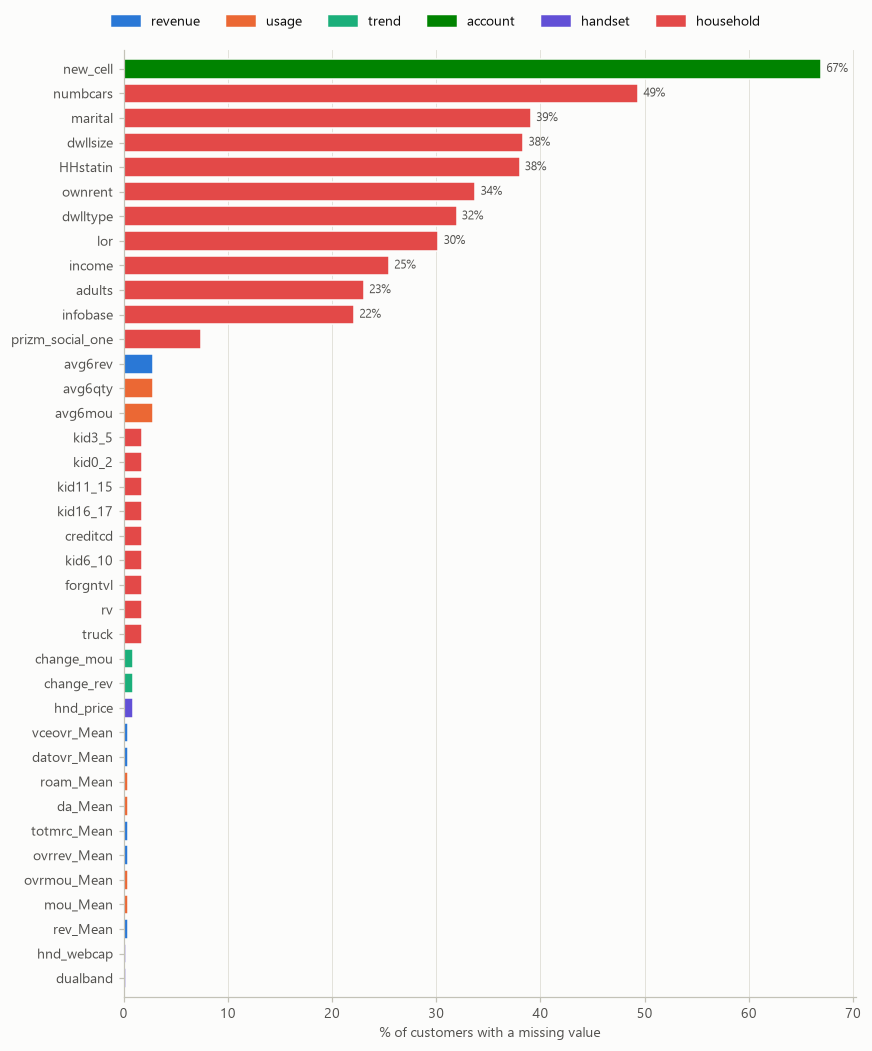

In [12]:
fig = plots.plot_missing(prof, colors, e["min_pct_missing"])

**Takeaway:** missing values (NaN, now including the unknown codes) are concentrated in the household (socio-demographic) family, 2–49% per field, and in the two columns whose unknown code is now missing: `new_cell` (67%) and `marital` (39%). Usage and billing columns are almost complete (< 3% missing).

In [13]:
blocks = eda.missing_blocks(df[features], e["min_pct_missing"])
blocks

,representative,n_columns,pct_missing,columns
0,new_cell,1,66.9312,new_cell
1,numbcars,1,49.3875,numbcars
2,marital,1,39.0862,marital
3,dwllsize,1,38.3525,dwllsize
4,HHstatin,1,37.9925,HHstatin
5,ownrent,1,33.7500,ownrent
6,dwlltype,1,31.9437,dwlltype
7,lor,1,30.2075,lor
8,income,1,25.4638,income
9,adults,1,23.0613,adults


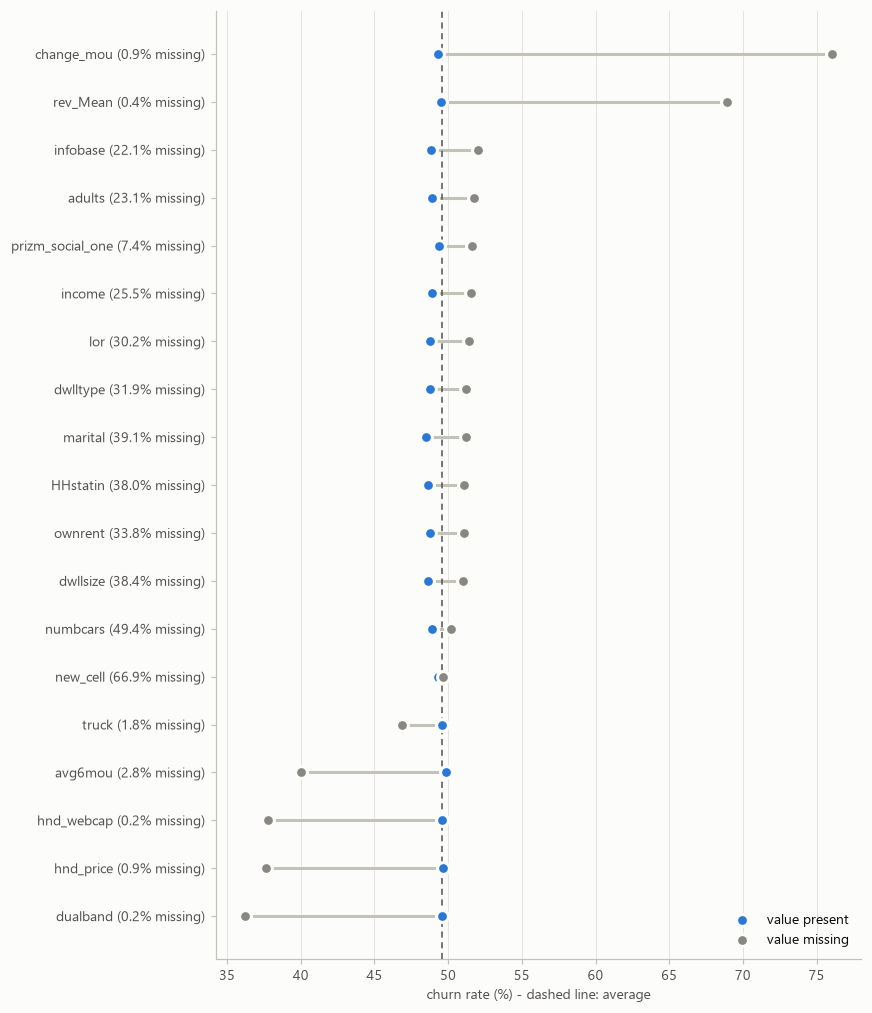

In [14]:
mvc = eda.flag_vs_churn(df[blocks["representative"]].isna(), df[TARGET])
fig = plots.plot_missing_vs_churn(mvc, overall)

The same comparison as a table, with the odds ratio (missing vs present, the effect size) and the FDR-adjusted chi-square p-value: one row per missing block, named by its first column (see the table above). The unknown codes are missing values since section A.

In [15]:
with pd.option_context("display.float_format", P_FORMAT):
    display(mvc.sort_values("odds_ratio", ascending=False, ignore_index=True))

,variable,n_flagged,pct_flagged,churn_flagged,churn_rest,odds_ratio,p_value,p_fdr
0,change_mou,718,0.898,0.76,0.493,3.26,4.07e-46,7.74e-45
1,rev_Mean,293,0.366,0.689,0.495,2.27,2.99e-11,7.11e-11
2,infobase,17696,22.1,0.52,0.489,1.14,8.06e-14,5.1e-13
3,adults,18449,23.1,0.518,0.489,1.12,6.43e-12,2.35e-11
4,marital,31269,39.1,0.512,0.485,1.11,1.13e-13,5.38e-13
5,income,20371,25.5,0.515,0.489,1.11,7.08e-11,1.35e-10
6,lor,24166,30.2,0.514,0.488,1.11,7.43e-12,2.35e-11
7,HHstatin,30394,38,0.511,0.486,1.1,1.87e-11,5.07e-11
8,dwlltype,25555,31.9,0.512,0.488,1.1,1.66e-10,2.87e-10
9,dwllsize,30682,38.4,0.51,0.486,1.1,5.3e-11,1.12e-10


Why are the 6-month averages missing? Share of customers without `avg6mou`, by tenure (8 = 8 months or more).

In [16]:
tenure = df["months"].clip(upper=8).rename("months")
df["avg6mou"].isna().groupby(tenure).agg(customers="size", avg6_missing="sum", share="mean")

,customers,avg6_missing,share
months,,,
6,1047,1047,1.0000
7,3985,1028,0.2580
8,74968,195,0.0026


**Takeaway:** missingness goes with churn in both directions. Its size, not its p-value, decides the treatment: every block except `new_cell` passes FDR, yet most effects are tiny.
- **Strong**: no `change_mou` (76% churn, OR 3.26 against customers who have it) and the 9-column billing block (OR 2.27). Churn is *lower* when `hnd_price` is missing (OR 0.61) and in the small unknown groups of `hnd_webcap` (OR 0.62) and `dualband` (OR 0.58), about 190 customers each. These are candidates for a **missing indicator** next to the imputed value.
- **Structural**: the 6-month averages (OR 0.67) are missing for every customer with 6 months of tenure and for 26% of those with 7, against 0.3% beyond: there are not six months of history yet. Their lower churn is the low churn of new customers (section 9), so an indicator would mostly repeat `months`.
- **Negligible**: the household fields, `marital` included (OR 1.05–1.14), and the `truck` block (OR 0.90, only just significant). Plain imputation is enough, and missingness of up to 49% is not by itself a reason to drop a field.
- **`new_cell` carries nothing**: its unknown code covers 67% of customers, who churn like the rest (OR 1.01, not significant).
- The `NA` of `hnd_webcap` (10% of customers) is a level, not a missing value (section A); its effect shows in the ranking of section 5.

## 5. Ranking against churn
Two predictive measures per variable:
- **|AUC − 0.5|** captures monotonic effects and gives a direction (`+`: higher value → more churn). Numbers use their present values only; missingness is measured in section 4. Categoricals use a cross-fitted target encoding (5 folds, so a category is never scored with its own rows' churn; Missing is a level), so they have no direction.
- **Mutual information on discretised features** (in nats) captures any shape. Numbers are cut into deciles, and Missing is its own bin. Categoricals keep their 10 most frequent levels and pool the rest into Other, so every variable has about 10 bins (MI grows with the number of bins by chance alone).
- **The 10-level cap is a compromise, not a neutral correction.** Rare levels lose their information: `crclscod` (53 levels in the training set) drops from MI 0.0034 to 0.0024, `area` (19) from 0.0013 to 0.0005, while `dwllsize` (15) is unchanged. Their cross-fitted AUC uses every level and is the check on what the cap loses.
- **Zero-inflated columns get MI = 0.** When ≥ 90% of a column is zero, its deciles collapse into one bin; the signal of those columns is read from the small-group table in section 2.

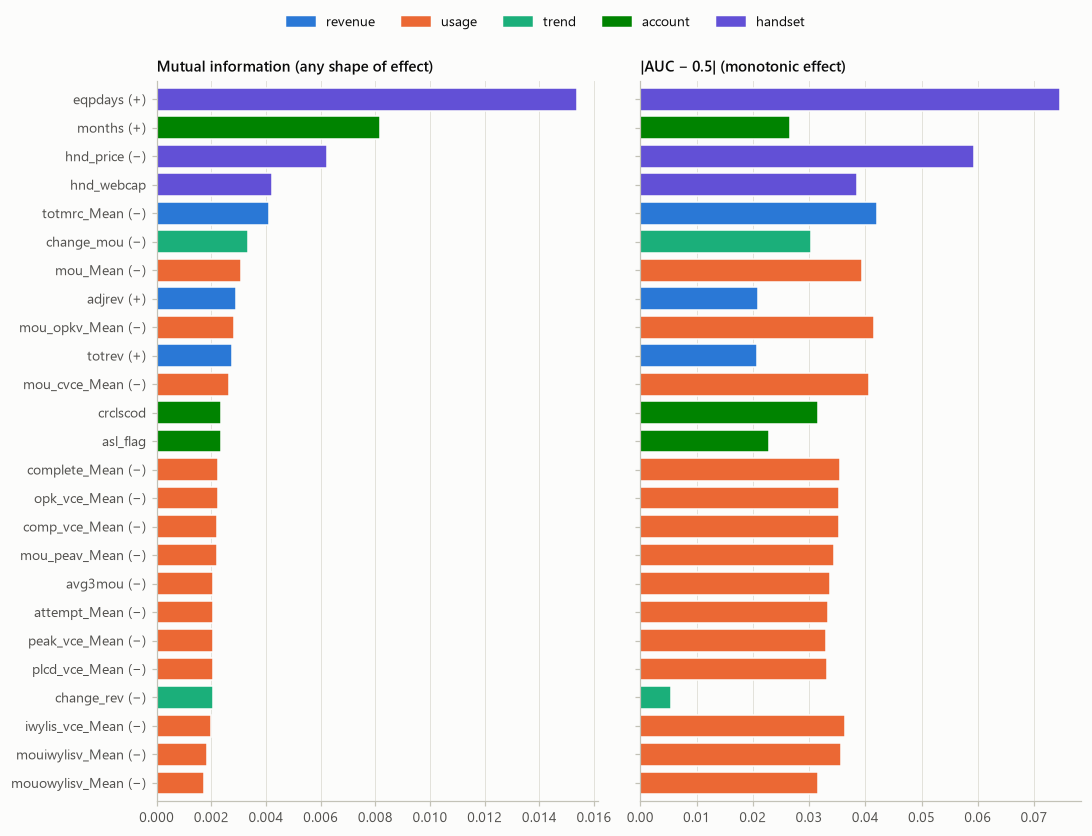

In [17]:
rank = eda.rank_vs_target(df, TARGET, families, e["n_bins"], cfg["seed"])
fig = plots.plot_ranking(rank, colors, e["top_n_ranking"])

**Essential tests, effect size first.**
- **Numbers**: Mann-Whitney U on present values. The effect size is the rank-biserial correlation *r* = 2·AUC − 1, from −1 to 1; > 0 means churners have higher values.
- **Categoricals**: chi-square with Missing as a level. Levels whose expected count is below 5 are pooled into Other, for the test only (`levels_merged`). The effect size is Cramér's V, from 0 to 1.
- p-values are Benjamini-Hochberg adjusted over the 97 tests (`p_fdr`). The table is sorted by MI: **p-values are not a ranking**. With 80,000 training customers, a single test already flags |r| ≈ 0.008 (AUC 0.504) as significant, so decisions rest on effect sizes and on the predictive measures.

In [18]:
tests = eda.tests_vs_target(df, TARGET, e["chi2_min_expected"])
table = rank.merge(tests, on="variable").join(prof["n_unique"], on="variable")
significant = table["p_fdr"] < 0.05
print(f"{significant.sum()} of {len(table)} variables significant at 5% FDR; "
      f"{(significant & (table['auc_strength'] < 0.02)).sum()} of them with |AUC - 0.5| < 0.02")
cols = ["variable", "family", "kind", "n_unique", "mi", "rank_mi", "auc", "direction", "rank_auc", "effect_size",
        "p_fdr", "levels_merged", "coverage"]
with pd.option_context("display.float_format", P_FORMAT):
    display(table[cols])

84 of 97 variables significant at 5% FDR; 42 of them with |AUC - 0.5| < 0.02


,variable,family,kind,n_unique,mi,rank_mi,auc,direction,rank_auc,effect_size,p_fdr,levels_merged,coverage
0,eqpdays,handset,numeric,1517,0.0154,1,0.575,+,1,0.149,6.65e-291,0,1
1,months,account,numeric,56,0.00816,2,0.527,+,29,0.0534,1.16e-38,0,1
2,hnd_price,handset,numeric,17,0.00622,3,0.441,-,2,-0.118,5.68e-187,0,0.991
3,hnd_webcap,handset,categorical,3,0.00424,4,0.539,,7,0.0919,1.34e-144,0,0.998
4,totmrc_Mean,revenue,numeric,7343,0.00412,5,0.458,-,3,-0.0841,6.53e-93,0,0.996
5,change_mou,trend,numeric,7182,0.00335,6,0.47,-,22,-0.0606,7.16e-49,0,0.991
6,mou_Mean,usage,numeric,9140,0.00307,7,0.461,-,6,-0.079,5.28e-82,0,0.996
7,adjrev,revenue,numeric,63280,0.0029,8,0.521,+,40,0.042,1.92e-24,0,1
8,mou_opkv_Mean,usage,numeric,50967,0.00283,9,0.459,-,4,-0.083,1.41e-90,0,1
9,totrev,revenue,numeric,63997,0.00275,10,0.521,+,41,0.0415,7.22e-24,0,1


In [19]:
rank.groupby("family")["mi"].max().sort_values(ascending=False).to_frame("best MI in family")

,best MI in family
family,
handset,0.0154
account,0.0082
revenue,0.0041
trend,0.0034
usage,0.0031
care,0.0015
household,0.0010
quality,0.0008


**Takeaway:** handset age (`eqpdays`) is the strongest variable on both measures, while `months` is 2nd by MI but only 29th by AUC: a non-monotonic effect that a linear term would miss. No single variable is strong on its own (best AUC 0.575, rank-biserial 0.149). The handset family leads (`eqpdays`, `hnd_price` and `hnd_webcap` are 1st, 3rd and 4th by MI), then account and revenue; network quality and household carry the least. Capping the categorical levels moves `crclscod` from MI rank 6 to 12. **Significance says little here:** 84 of 97 variables pass 5% FDR, 42 of them with |AUC − 0.5| < 0.02.

## 6. Churn rate by decile
One representative per family, best first by mutual information, with `months` and `eqpdays` always included. Grey bar: customers with a missing value; dashed line: average churn rate; label: odds ratio (OR) of the riskiest bin against the average.

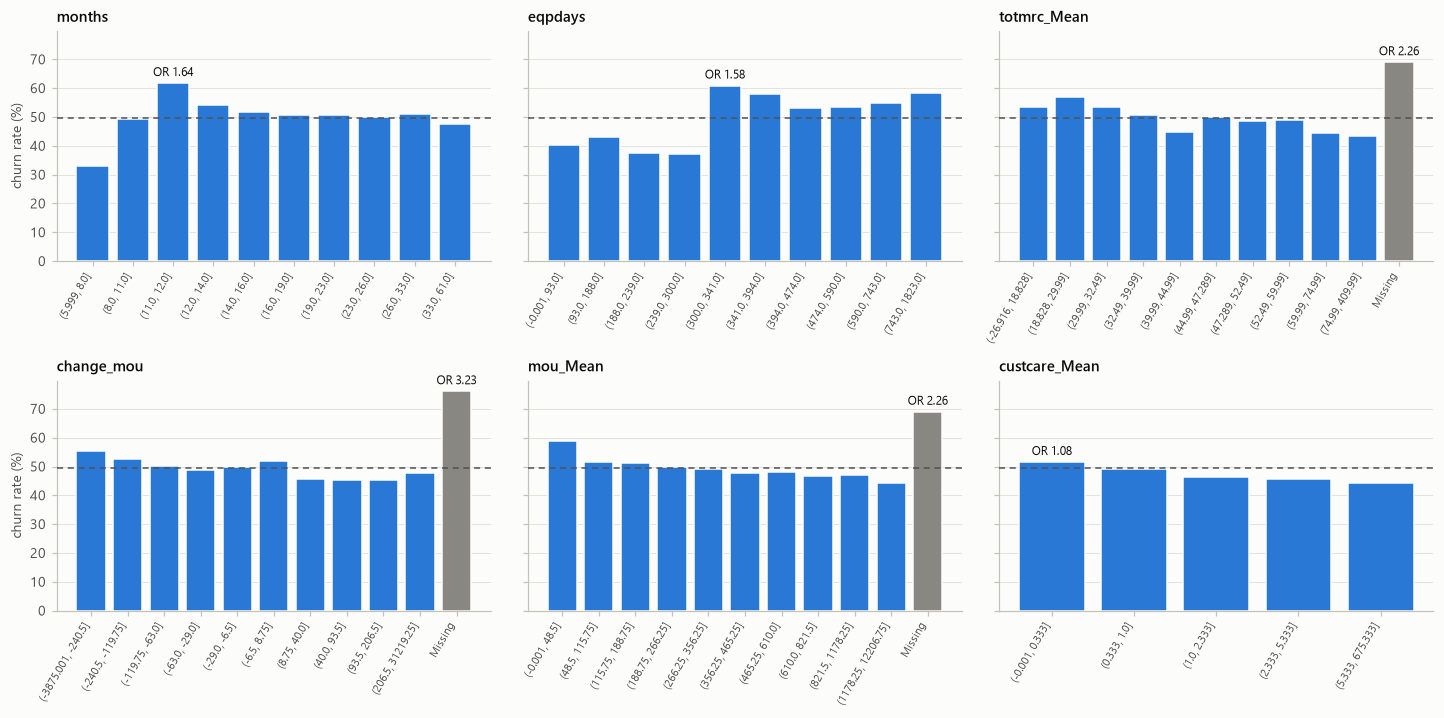

In [20]:
reps = eda.pick_representatives(rank, e["n_representatives"], e["must_include"])
deciles = {v: eda.churn_by_bin(df, v, TARGET, e["n_bins"], e["min_bin_size"]) for v in reps}
fig = plots.plot_churn_by_bin(deciles, overall)

**Takeaway:** one variable per family confirms the ranking: risk peaks at 12 months of tenure (OR 1.64; month 11 shares a decile with months 9–10, see section 9) and at 301–341 days of handset age (OR 1.58), falls as usage and monthly charge rise, jumps when usage history is missing (OR 2.3–3.2), and is lowest for customers who call customer care most (44% vs 52% with no calls, OR 0.81 vs 1.08), an association to check, not a cause.

## 7. Redundancy among numeric variables
Spearman correlation (rank-based, robust to the long tails), computed pairwise on available values over **all 77 numeric columns**.
- The heatmap shows only the 20 strongest variables by MI, so that it stays readable. The pair table and the groups use the full matrix.
- **Pairs** with |ρ| ≥ 0.8 are listed; `extreme` marks |ρ| ≥ 0.9.
- **Groups** chain those pairs (connected components). Members can be linked only indirectly (a~b and b~c while a and c are weakly related), so `min_abs_corr` gives the weakest pair inside each group: a group is a set to inspect, not a set to drop.
- Groups are statistical and are not the semantic families. Nothing is dropped here; candidates are listed in section 11.

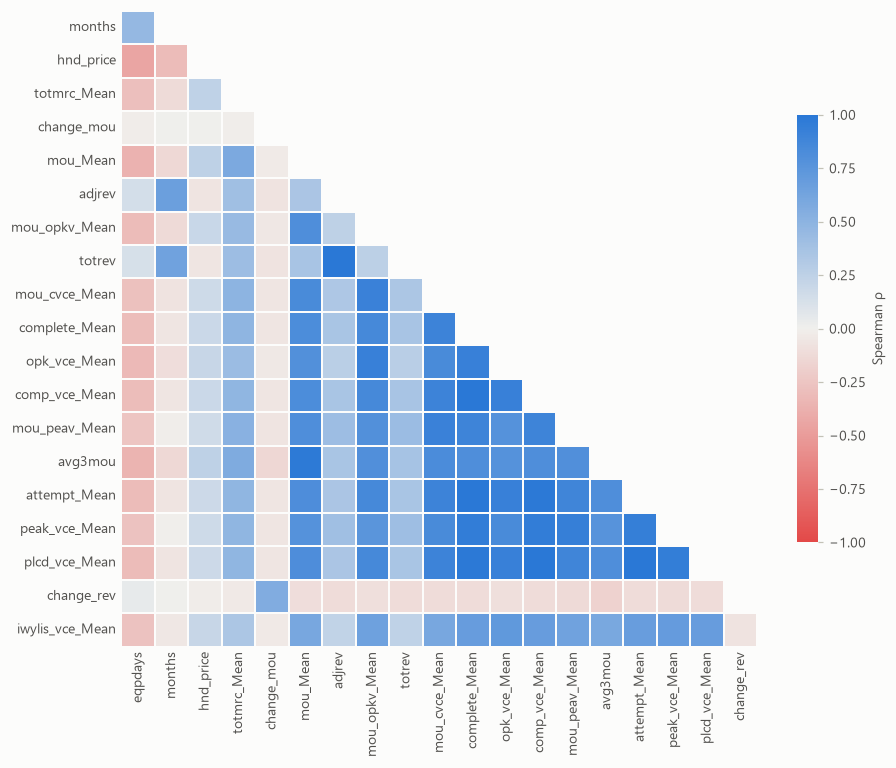

In [21]:
top_numeric = rank.loc[rank["kind"] == "numeric", "variable"].head(e["top_n_corr"]).tolist()
corr = df[top_numeric].corr(method="spearman")
fig = plots.plot_corr(corr)

In [22]:
numeric = prof.index[prof["kind"] == "numeric"]
corr_all = df[numeric].corr(method="spearman")
pairs = eda.redundant_pairs(corr_all, e["corr_threshold"])
pairs["extreme"] = pairs["corr"].abs() >= e["redundancy_threshold"]
print(f"{len(pairs)} pairs with |rho| >= {e['corr_threshold']}, {pairs['extreme'].sum()} of them >= {e['redundancy_threshold']}")
eda.redundancy_groups(corr_all, e["corr_threshold"], families)

182 pairs with |rho| >= 0.8, 60 of them >= 0.9


,n_variables,min_abs_corr,families,variables
0,30,0.4877,"quality, usage","mou_Mean, drop_vce_Mean, unan_vce_Mean, plcd_vce_Mean, recv_vce_Mean, comp_vce_Mean, inonemin_Mean, mou_cvce_Mean, m..."
1,7,0.5409,usage,"plcd_dat_Mean, comp_dat_Mean, mou_cdat_Mean, peak_dat_Mean, mou_pead_Mean, opk_dat_Mean, mou_opkd_Mean"
2,4,0.8239,revenue,"rev_Mean, avgrev, avg3rev, avg6rev"
3,3,0.9768,"revenue, usage","ovrmou_Mean, ovrrev_Mean, vceovr_Mean"
4,3,0.9727,care,"custcare_Mean, ccrndmou_Mean, cc_mou_Mean"
5,2,0.8282,account,"uniqsubs, actvsubs"
6,2,0.9957,revenue,"totrev, adjrev"
7,2,0.9050,handset,"phones, models"


In [23]:
pairs

,var_a,var_b,corr,extreme
0,totcalls,adjqty,0.9995,True
1,totmou,adjmou,0.9995,True
2,plcd_vce_Mean,attempt_Mean,0.9993,True
3,peak_dat_Mean,mou_pead_Mean,0.9992,True
4,comp_vce_Mean,complete_Mean,0.9991,True
5,comp_dat_Mean,mou_cdat_Mean,0.9989,True
6,opk_dat_Mean,mou_opkd_Mean,0.9987,True
7,ccrndmou_Mean,cc_mou_Mean,0.9981,True
8,ovrmou_Mean,ovrrev_Mean,0.9978,True
9,totrev,adjrev,0.9957,True


**Takeaway:** the usage family is one signal measured many times. 30 variables, from usage plus the voice quality counters (`drop_vce_Mean`, `drop_blk_Mean`), chain into one group at |ρ| ≥ 0.8, yet the weakest pair inside it is only 0.49, so the group is a set of related signals rather than one variable. Smaller groups are tighter: overage minutes and revenue (ρ ≥ 0.97, spanning revenue and usage), customer-care calls and minutes (≥ 0.97), `totrev`/`adjrev` (0.996), the revenue averages (≥ 0.82), the data-call counters, `uniqsubs`/`actvsubs` and `phones`/`models`. Importance should be read per group or family, and which members to keep is tested in modelling (section 11).

## 8. Outliers
Box plots by churn class on a **symlog** axis: linear within ±10 and logarithmic beyond, so zeros and negative values stay on the chart (a plain log cannot show them). It is a display scale only: the data are not transformed.

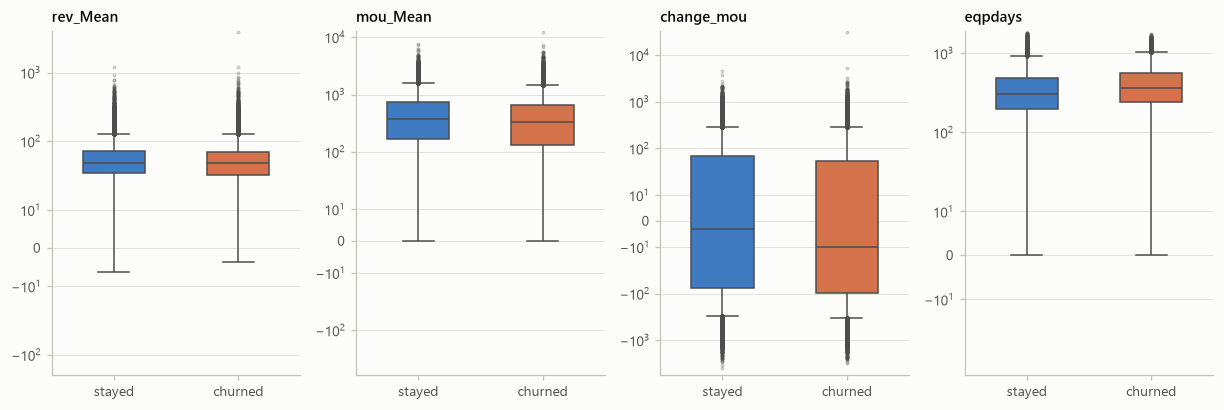

In [24]:
fig = plots.plot_outliers(df, e["outlier_variables"], TARGET)

In [25]:
prof.loc[e["outlier_variables"], ["pct_negative", "min", "median", "max", "skew"]]

,pct_negative,min,median,max,skew
rev_Mean,0.0063,-6.1675,48.2575,3843.2625,10.3020
mou_Mean,0.0000,0.0000,356.2500,12206.7500,2.3405
change_mou,54.1825,-3875.0000,-6.5000,31219.2500,17.0172
eqpdays,0.0000,0.0000,341.0000,1823.0000,1.0475


**Takeaway:** unusual values fall into three kinds, and each is treated differently.
- **Domain errors**: only the negative handset ages, clipped to 0 in section A. The other violations found there are kept as plausible.
- **Special codes**: the U/UNKW codes of four categoricals, now missing values (section A).
- **Plausible extremes**: heavy users and big spenders, present in both classes. `rev_Mean` reaches 3,843 against a median of 48. `change_mou` runs from −3,875 to +31,219: a difference in minutes, not the percentage its description suggests (section A).

Nothing is clipped or transformed here. For linear models a plain log is impossible where values are negative (`change_*`, `rev_Mean`, `totmrc_Mean`, `avg6rev`), so the choice between a signed log, quantile or robust scaling, or trees only is a modelling decision.

## 9. Focus: tenure and handset age
The two strongest variables at full resolution: one bar per month of tenure (36 = 36 months or more) and 30-day bands of handset age (label = start of the band).

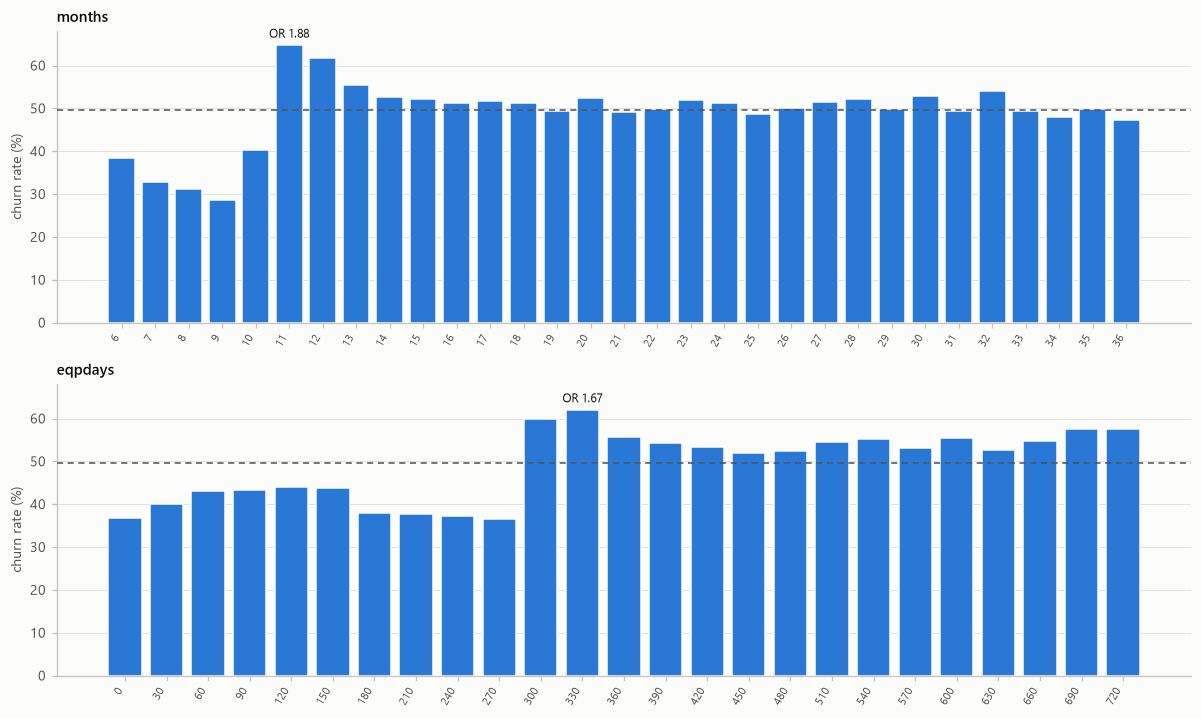

In [26]:
focus = {v: eda.churn_by_bin(df, v, TARGET, bins, e["min_bin_size"]) for v, bins in e["focus_bins"].items()}
fig = plots.plot_churn_by_bin(focus, overall, ncols=1)

**Takeaway:** churn is low in months 6–10 (29–40%, OR 0.41–0.69), jumps to 65% at month 11 (OR 1.88, about twice the average risk) and 62% at month 12 (OR 1.64), then settles around 50%. Handset age shows a similar step: 37–44% below 300 days, 60–62% at 300–359 days (OR 1.52–1.67). The data hold no contract information, so "the end of a 12-month commitment" is a hypothesis consistent with this shape, not a finding.

### Tenure × handset age: one phenomenon or two?
Handset age never exceeds tenure here (by more than the rounding of whole months), so the two peaks could be the same customers: 11–12-month customers still on their first handset. The grid crosses coarse bands of both variables (bands in `config.yaml`; cells under 100 customers are blank).

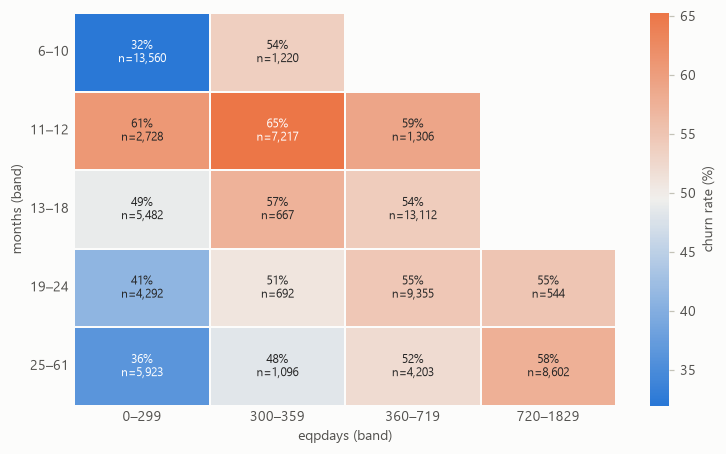

In [27]:
gb = e["grid_bins"]
grid = eda.churn_by_grid(df, "months", gb["months"], "eqpdays", gb["eqpdays"], TARGET, e["min_bin_size"])
fig = plots.plot_churn_grid(grid, overall, gb["months"], gb["eqpdays"])

**Takeaway:** the two peaks are **two partly independent signals**, not one.
- At 11–12 months churn is high whatever the handset age: 61% with a handset under 300 days, 65% at 300–359 days.
- A 300–359-day handset raises churn in every tenure band: 54% vs 32% at 6–10 months, 48% vs 36% at 25+ months. Handsets of 720+ days reach 55–58%.
- The peaks overlap (7,217 training customers are in both), but each variable carries information the other lacks, so both stay. An interaction term, or trees, can capture the combination.

## 10. Data quality and leakage checklist

In [28]:
tenure_band = pd.cut(train["months"], e["grid_bins"]["months"], right=False)
within = train.groupby(tenure_band, observed=True).apply(lambda g: roc_auc_score(g[TARGET], g["Customer_ID"]))
print(f"minimum tenure: {train['months'].min()} months; "
      f"Spearman(Customer_ID, months) = {train['Customer_ID'].corr(train['months'], method='spearman'):.2f}; "
      "AUC of Customer_ID within tenure bands:", within.round(3).rename(index=str).to_dict())
id_decile = pd.qcut(train["Customer_ID"], 10, labels=range(1, 11)).rename("Customer_ID decile")
train.groupby(id_decile, observed=True).agg(churn_rate=(TARGET, "mean"), median_months=("months", "median"),
                                            median_eqpdays=("eqpdays", "median"), median_mou=("mou_Mean", "median"))

minimum tenure: 6 months; Spearman(Customer_ID, months) = -0.83; AUC of Customer_ID within tenure bands: {'[6, 11)': 0.449, '[11, 13)': 0.508, '[13, 19)': 0.502, '[19, 25)': 0.495, '[25, 62)': 0.497}


,churn_rate,median_months,median_eqpdays,median_mou
Customer_ID decile,,,,
1,0.4944,36.0000,497.0000,295.5000
2,0.5180,28.0000,684.0000,285.0000
3,0.4940,23.0000,586.0000,295.7500
4,0.5024,21.0000,541.0000,306.0000
5,0.5240,17.0000,443.0000,369.7500
6,0.5537,14.0000,369.0000,385.5000
7,0.5349,12.0000,334.0000,376.2500
8,0.5054,11.0000,298.0000,414.7500
9,0.4517,10.0000,264.0000,435.6250


**Lifetime totals: where do they stop?** A lifetime total divided by the lifetime monthly average gives the number of months the total covers (`adjrev / avgrev`, `adjmou / avgmou`). Tenure minus that number = tenure months the total leaves out (4 = 4 or more). Compared across churn classes, it also shows whether churn cuts the totals short.

In [29]:
gap = (df["months"] - df["adjrev"] / df["avgrev"]).round().astype(int).clip(upper=4).rename("months not covered")
gap_mou = (df["months"] - df["adjmou"] / df["avgmou"].where(df["avgmou"] > 0)).round().clip(upper=4)
print(f"revenue and minutes totals leave out the same months for {(gap == gap_mou).mean():.1%} of customers")
pd.concat([gap.value_counts(normalize=True).rename("all"),
           pd.crosstab(gap, df[TARGET], normalize="columns").rename(columns={0: "stayed", 1: "churned"})],
          axis=1).sort_index()

revenue and minutes totals leave out the same months for 100.0% of customers


,all,stayed,churned
months not covered,,,
0,0.0001,0.0000,0.0001
1,0.6166,0.6251,0.6080
2,0.2720,0.2663,0.2778
3,0.0254,0.0250,0.0258
4,0.0859,0.0835,0.0883


- [x] **Identifiers.** `Customer_ID` is unique and never a feature. It is not in random order: it follows acquisition, with median tenure falling from 36 to 9 months across ID deciles. Churn varies with it (38% in the last decile), but within tenure bands the association almost disappears (AUC ≈ 0.50, 0.45 only at 6–10 months, where tenure itself still moves churn). This is why the split in section B is random rather than by ID.
  - **Open:** how the file was built, and whether customers share one observation date. A random split could still hide a time component or a drift between cohorts. Ask the data owner.
- [x] **Duplicates**: none (rows, IDs, rows ignoring the ID), checked on the whole file in section A, so no customer is in both the training and the hold-out set.
- [ ] **Post-event variables.** None is described as measured after the observation date, but the dictionary never states the reference date. To confirm:
  - `totrev`, `totmou`, `totcalls` and `adj*` ("over the life of the customer") would include the churn window if they were computed at extraction. **Partly checked** (table above): a total covers the tenure minus 1 month for 62% of customers and minus 2 for 27%, almost never the full tenure, and the shares are the same for churners and non-churners. So the totals share the tenure's reference date, stop before its last month, and are not cut short by churn. If `months` is measured at the observation date, the totals end before it, well before the churn window: that reference date is what remains to confirm.
  - A missing `change_mou` (76% churn) is legitimate if it means no usage in the month before observation, and leakage if that month overlaps the churn window.
  - The negative raw `eqpdays` (clipped in section A) suggest some handset dates fall a few days after the observation date.
- [x] **Time availability.** Monthly means, 3- and 6-month averages, tenure and handset age are all known at scoring time, if they are computed up to the observation date.
- [x] **Target definition.** Churn 31–60 days after observation leaves a 30-day gap after the features, enough for a retention action. Every customer has at least 6 months of tenure, so the model only applies to that population.

No feature is dropped for suspected leakage: the doubts are documented here and go to the data owner.

## 11. Candidates for removal (to be confirmed by the model comparison)
Two rules, both on predictive measures, never on p-values:
- **Near-duplicate**: walking from the highest MI down, a numeric variable with |ρ| ≥ 0.9 to one already kept. Every candidate therefore has a kept stand-in, which avoids the chaining problem of the groups.
- **Negligible signal**: |AUC − 0.5| < 0.01 (|r| < 0.02) and MI below the median.

This list is an input to modelling. Models are compared with and without it on cross-validation, and nothing is removed from the data here.

In [30]:
candidates = eda.removal_candidates(rank, corr_all, e["redundancy_threshold"], e["negligible_auc_strength"])
print({r: int(candidates["reason"].str.contains(r).sum()) for r in ["near-duplicate", "negligible signal"]})
with pd.option_context("display.float_format", P_FORMAT):
    display(candidates)

{'near-duplicate': 28, 'negligible signal': 32}


,variable,family,mi,auc_strength,reason
0,new_cell,account,8.85e-06,0.00133,"negligible signal (|AUC-0.5| 0.001, MI rank 88)"
1,ccrndmou_Mean,care,0.00143,0.0283,near-duplicate of custcare_Mean (rho 0.982)
2,cc_mou_Mean,care,0.00136,0.028,near-duplicate of custcare_Mean (rho 0.973)
3,phones,handset,0.000477,0.0225,near-duplicate of models (rho 0.905)
4,refurb_new,handset,0.000477,0.00877,"negligible signal (|AUC-0.5| 0.009, MI rank 57)"
5,income,household,0.000387,0.00448,"negligible signal (|AUC-0.5| 0.004, MI rank 66)"
6,adults,household,0.00034,0.00432,"negligible signal (|AUC-0.5| 0.004, MI rank 70)"
7,ownrent,household,0.000248,0.00931,"negligible signal (|AUC-0.5| 0.009, MI rank 76)"
8,prizm_social_one,household,0.000246,0.00696,"negligible signal (|AUC-0.5| 0.007, MI rank 77)"
9,creditcd,household,0.000187,0.00738,"negligible signal (|AUC-0.5| 0.007, MI rank 78)"


**Takeaway:** 55 of 97 variables are candidates, so a much smaller model may lose little. That is a hypothesis for the model comparison, not a decision. The list has 28 near-duplicates (mostly usage, plus `totrev`, `avg3rev`/`avg6rev`, `ovr*`, the care minutes and `phones`) and 32 variables with negligible signal (most household fields, the data/SMS counters, roaming, `new_cell`), with 5 meeting both rules. Three caveats before dropping:
1. The near-constant counters look negligible on AUC and MI, but their non-zero minority churns less (section 2). Test a 0/1 indicator first.
2. Several household fields carry a small missingness signal (section 4).
3. Between near-duplicates the higher MI wins, but the more interpretable one may be preferable for the business story (e.g. `totrev` vs `adjrev`).

## Conclusions

**Data conformity (whole file, section A)**
1. Missing values are empty cells only. The literal `NA` in `hnd_webcap` is a level (a handset type); four unknown codes (`new_cell`, `marital` and `dualband` U, `hnd_webcap` UNKW) became NaN.
2. 85 of 93 domain checks hold. The 133 negative handset ages were clipped to 0. The other violations (a few negative charges, 81 customers with no active subscriber, small billing mismatches) are kept as plausible.
3. `change_mou` and `change_rev` are differences, not the percentages the dictionary describes. There are no duplicates.

**Observed in the training set**
1. Churn prevalence is 49.6%; whether that is natural or sampled is undocumented.
2. **Handset age** (`eqpdays`) is the strongest single variable (AUC 0.575, MI #1). **Tenure** (`months`) is MI #2 but AUC #29: its effect is non-monotonic. No variable is strong on its own.
3. Two risk peaks: tenure of 11–12 months (62–65%) and handset age of 300–359 days (60–62%). The grid shows they are partly independent.
4. A missing usage history goes with churn (no `change_mou`: OR 3.26; billing block: OR 2.27), while missing household fields barely matter (OR 1.05–1.14).
5. Lower and declining usage and a lower monthly charge go with more churn; heavy customer-care callers churn less.
6. Strong redundancy: 182 numeric pairs at |ρ| ≥ 0.8 (60 at ≥ 0.9), with one 30-variable usage group.
7. 84 of 97 variables are significant after FDR, 42 of them with a negligible effect: significance is not relevance.
8. `Customer_ID` follows acquisition order, which explains its association with churn.

**Hypotheses to verify**
- The 50% prevalence comes from sampling on churn. Ask the data owner; if so, recalibrate the probabilities.
- The month 11–12 peak marks the end of a 12-month commitment. There is no contract data to confirm it.
- `NA` in `hnd_webcap` means no web capability, and the negative `eqpdays` were a few-day date offset.
- A missing `change_mou` means inactivity before the churn window, not leakage. The lifetime totals stop 1–2 months before the tenure's reference date, in the same way for both classes (section 10); that this date is the observation date is still to confirm.
- Heavy care callers are more engaged customers. This is an association only.

**Implications for preprocessing** (inside the sklearn `Pipeline`, fitted on the training set only)
- `clean()` as the first step, so the pickle applies the same conformity rules to new customers.
- Missing indicators for the informative blocks (`change_*`, the billing block, `hnd_price`); plain imputation elsewhere. A missing `avg6*` only marks a tenure of 6–7 months, so its indicator would repeat `months`.
- A missing categorical becomes its own category, never the mode: this keeps the signal of the recoded unknown codes.
- Near-constant counters: keep them as they are, or recode as 0/1 non-zero indicators.
- Long tails and negative values: signed log or quantile transform for linear models only. No clipping.

**Deferred to modelling**
- Which section 11 candidates to drop: compare models with and without them on cross-validation.
- How to capture the non-monotonic tenure effect and the tenure × handset-age combination: splines/GAM, trees, or an interaction term.
- Calibration of probabilities, if the prevalence turns out to be sampled.
- Expected performance: measured with cross-validation and on the hold-out set, not inferred from univariate AUCs.

Everything here is association, not causation: the model will say *who* is at risk, while *which action* retains them needs testing, for example with a controlled retention campaign.